# Training, frozen selection and later test evaluation
Synthetic results verify software only. No operational skill claim is supported.

In [1]:
from pathlib import Path
import json
from firecast.fixture import create_fixture
from firecast.cli import prepare
from firecast.models import train_experiments
root = Path.cwd() if (Path.cwd() / 'configs').exists() else Path.cwd().parent
config=json.loads((root / 'configs/lebanon.json').read_text())
cfg=create_fixture(root / 'data/notebook-fixture', config)
datasets, provenance=prepare(root / 'data/notebook-fixture', cfg, root / 'outputs/notebook')
report=train_experiments(datasets,cfg,root / 'outputs/notebook',provenance)

In [2]:
import pandas as pd
pd.DataFrame([{'experiment':r['id'],'validation_brier':r['validation']['brier'],'test_pr_auc':r['test']['pr_auc_average_precision'],'test_brier':r['test']['brier'],'positive_test_windows':r['test']['positive_windows']} for r in report['experiments']])

,experiment,validation_brier,test_pr_auc,test_brier,positive_test_windows
0,conservative-lebanon-seasonal,0.030370,0.079433,0.038500,40
1,conservative-lebanon-weather,0.029676,0.129163,0.038459,40
2,conservative-lebanon-environment,0.029743,0.123570,0.038460,40
3,conservative-regional-seasonal,0.030288,0.078764,0.038476,40
4,conservative-regional-weather,0.029665,0.147197,0.038326,40
5,conservative-regional-environment,0.029614,0.145505,0.038335,40
6,strict-lebanon-seasonal,0.028488,0.060105,0.031656,32
7,strict-lebanon-weather,0.027983,0.096675,0.031896,32
8,strict-lebanon-environment,0.028083,0.069385,0.032036,32
9,strict-regional-seasonal,0.028439,0.059580,0.031617,32


(0.0, 1.0)

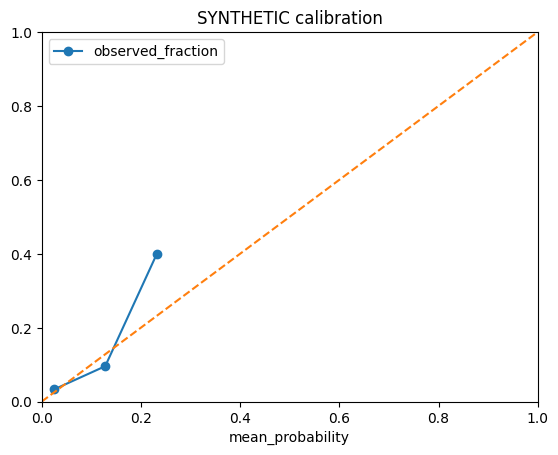

In [3]:
selected=next(r for r in report['experiments'] if r['id']==report['selected'])
cal=pd.DataFrame(selected['test']['calibration'])
ax=cal.plot(x='mean_probability',y='observed_fraction',marker='o',title='SYNTHETIC calibration')
ax.plot([0,1],[0,1],'--'); ax.set_xlim(0,1); ax.set_ylim(0,1)

Thresholds maximize validation F1 and are research screening choices, not emergency action thresholds. Check Brier, reliability bins, weekly bootstrap intervals, split counts and seasonal groups. Regional fixture comparisons cannot justify pooling real Cyprus data. Class weighting and subsampling are disabled. Deep learning and global training are deferred.